# Leakage-Aware Life Insurance Churn: Independent Reproduction & Figure Audit

**Purpose:** Verify core tables and reproduce Figures 3–5 inline. This is an **independent implementation**, not the original authors’ code. The notebook does not save image files.

**Input:** `randomdata.csv` in the same folder as this notebook (also searches `/mnt/data/randomdata.csv`). Run **Kernel → Restart & Run All**. Reconcile flagged mismatches with the manuscript before submission.

**Protocol:** Scenario A: conventional stratified 80/20 split, BMI retained (seed 10). Scenario B: BMI excluded; `GroupShuffleSplit(test_size=0.2)` using identical predictor vectors, seeds 0–9, independent representative split seed 10. LR max_iter=400; RF and GB n_estimators=60. Bootstrap: 1,000 stratified observation-level resamples (NOT group bootstrap). K-means uses standardized Claim Amount and Category Premium; silhouette estimates use a reproducible sample of 3,000 records.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, roc_curve,
                             silhouette_score, davies_bouldin_score)
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import chi2_contingency

SEEDS=list(range(10)); REPRESENTATIVE_SEED=10; BOOTSTRAP_SEED=2026
N_BOOTSTRAP=1000; KMEANS_SEED=42; SIL_SAMPLE_SIZE=3000
pd.set_option('display.max_columns',25)
paths=[Path('randomdata.csv'),Path('/mnt/data/randomdata.csv')]
source=next((p for p in paths if p.exists()),None)
if source is None: raise FileNotFoundError('Place randomdata.csv next to this notebook.')
df=pd.read_csv(source)
print('Source:',source,'shape:',df.shape)
display(df.head(3))

Source: randomdata.csv shape: (200000, 12)


,Unnamed: 0,Customer Name,Customer_Address,Company Name,Claim Reason,Data confidentiality,Claim Amount,Category Premium,Premium/Amount Ratio,Claim Request output,BMI,Churn
0,0,Christine Payne,"7627 Anderson Rest Apt. 265,Lake Heather, DC 3...","Williams, Henderson and Perez",Travel,Low,377,4794,0.078640,No,21,Yes
1,1,Tony Fernandez,"3953 Cindy Brook Apt. 147,East Lindatown, TN 4...",Moore-Goodwin,Medical,High,1440,14390,0.100069,No,24,Yes
2,2,Christopher Kim,"8693 Walters Mountains,South Tony, TX 88407",Smith-Holmes,Phone,Medium,256,1875,0.136533,No,18,Yes


## 1. Dataset audit: counts, BMI, redundancy and duplicates

Duplicate definition is **number of redundant occurrences beyond the first row of each distinct predictor vector**. This is different from the share of rows *belonging to* a duplicated group. Churn is **excluded** from grouping; in Scenario B BMI is also excluded.

In [2]:
identifier_columns=['Customer Name','Customer_Address','Company Name']
index_columns=['Unnamed: 0']
TARGET='Churn'
FEATURES=[c for c in df.columns if c not in identifier_columns+index_columns+[TARGET]]
FEATURES_B=[c for c in FEATURES if c!='BMI']
CAT_COLS=['Claim Reason','Data confidentiality','Claim Request output']
NUM_COLS_A=['Claim Amount','Category Premium','Premium/Amount Ratio','BMI']
NUM_COLS_B=[x for x in NUM_COLS_A if x!='BMI']
y=(df[TARGET].str.strip().str.lower()=='yes').astype(int)
assert len(df)==200_000 and not df[FEATURES+[TARGET]].isna().any().any()
summary=[]
for label,cols in [('With BMI',FEATURES),('Without BMI',FEATURES_B)]:
    unique=len(df[cols].drop_duplicates()); redundant=len(df)-unique
    sizes=df.groupby(cols,dropna=False).size()
    group_members=int(sizes[sizes>1].sum())
    summary.append({'Predictors':label,'n_records':len(df),'n_unique_vectors':unique,
                    'n_redundant_occurrences':redundant,'redundancy_pct':100*redundant/len(df),
                    'records_in_duplicate_groups':group_members,'pct_in_duplicate_groups':100*group_members/len(df)})
display(pd.DataFrame(summary))
print('Churn prevalence:',y.mean())
print('BMI x churn:');display(pd.crosstab(df['BMI'],df[TARGET]))
print('Claim Reason x Category Premium:');display(pd.crosstab(df['Claim Reason'],df['Category Premium']))
err=np.abs(df['Premium/Amount Ratio']-df['Claim Amount']/df['Category Premium'])
print('Maximum absolute ratio error:',err.max())
stump=DecisionTreeClassifier(max_depth=1,random_state=10).fit(df[['BMI']],y)
print('BMI-only stump accuracy:',stump.score(df[['BMI']],y),'threshold:',stump.tree_.threshold[0])
# Shared feature vector can have both labels: informational, not a guarantee of zero predictive signal
n_both=(df.groupby(FEATURES_B,dropna=False)[TARGET].nunique()==2).sum()
print('BMI-excluded feature vectors associated with both classes:',n_both)
assert len(df[FEATURES].drop_duplicates())==19373
assert len(df[FEATURES_B].drop_duplicates())==1769

,Predictors,n_records,n_unique_vectors,n_redundant_occurrences,redundancy_pct,records_in_duplicate_groups,pct_in_duplicate_groups
0,With BMI,200000,19373,180627,90.3135,199675,99.8375
1,Without BMI,200000,1769,198231,99.1155,200000,100.0000


Churn prevalence: 0.63636
BMI x churn:


Churn,No,Yes
BMI,,
18,0,18293
19,0,18177
20,0,17899
21,0,18035
22,0,18072
23,0,18433
24,0,18363
25,18061,0
26,17988,0


Claim Reason x Category Premium:


Category Premium,399,1875,4794,14390
Claim Reason,,,,
Medical,0,0,0,109863
Other,30187,0,0,0
Phone,0,30016,0,0
Travel,0,0,29934,0


Maximum absolute ratio error: 9.71445146547012e-17
BMI-only stump accuracy: 1.0 threshold: 24.5
BMI-excluded feature vectors associated with both classes: 1769


## 2. Group-aware representative split and Table 2

All rows sharing a **BMI-excluded** predictor vector are assigned to one partition. `test_size=0.2` refers to **number of groups**; the number of rows need not be exactly 20%.

In [3]:
group_ids=pd.util.hash_pandas_object(df[FEATURES_B],index=False)
def group_split(seed):
    splitter=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=seed)
    train_idx,test_idx=next(splitter.split(df,y,groups=group_ids))
    assert set(group_ids.iloc[train_idx]).isdisjoint(set(group_ids.iloc[test_idx]))
    return train_idx,test_idx
train_rep,test_rep=group_split(REPRESENTATIVE_SEED)
def table2_row(mask,part):
    current=df.iloc[part]; rule=(current['BMI']<=24) if mask else (current['BMI']>=25)
    matching=((current[TARGET]=='Yes') if mask else (current[TARGET]=='No')) & rule
    return f'{matching.sum():,} / {rule.sum():,}'
all_idx=np.arange(len(df))
rows=[]
for flag,name in [(True,'BMI ≤ 24 → Churn = Yes'),(False,'BMI ≥ 25 → Churn = No')]:
    rows.append({'BMI band':name,'All (n=200,000)':table2_row(flag,all_idx),
                 f'Train (n={len(train_rep):,})':table2_row(flag,train_rep),
                 f'Test (n={len(test_rep):,})':table2_row(flag,test_rep)})
table2=pd.DataFrame(rows);display(table2)
assert (len(train_rep),len(test_rep))==(157620,42380)

,BMI band,"All (n=200,000)","Train (n=157,620)","Test (n=42,380)"
0,BMI ≤ 24 → Churn = Yes,"127,272 / 127,272","100,267 / 100,267","27,005 / 27,005"
1,BMI ≥ 25 → Churn = No,"72,728 / 72,728","57,353 / 57,353","15,375 / 15,375"


## 3. Scenario A and Scenario B models

Model settings documented here are the settings of this independent reproduction. Outputs should be treated as updated manuscript results **only after** comparison with Tables 3 and the text.

In [4]:
def make_pipeline(name,with_bmi,seed):
    nums=NUM_COLS_A if with_bmi else NUM_COLS_B
    pre=ColumnTransformer([('cat',OneHotEncoder(handle_unknown='ignore'),CAT_COLS),
                           ('num',StandardScaler(),nums)])
    if name=='Logistic Regression': model=LogisticRegression(max_iter=400,random_state=seed)
    elif name=='Random Forest': model=RandomForestClassifier(n_estimators=60,random_state=seed,n_jobs=-1)
    elif name=='Gradient Boosting': model=GradientBoostingClassifier(n_estimators=60,random_state=seed)
    elif name=='Majority baseline': model=DummyClassifier(strategy='most_frequent')
    else: raise ValueError(name)
    return Pipeline([('preprocess',pre),('classifier',model)])
def score_model(fitted,X,ytrue):
    pred=fitted.predict(X);proba=fitted.predict_proba(X)[:,1]
    return {'Accuracy':accuracy_score(ytrue,pred),
            'Precision':precision_score(ytrue,pred,zero_division=0),
            'Recall':recall_score(ytrue,pred,zero_division=0),
            'F1':f1_score(ytrue,pred,zero_division=0),
            'Balanced Accuracy':balanced_accuracy_score(ytrue,pred),
            'AUC-ROC':roc_auc_score(ytrue,proba),
            'Positive Prediction Rate':float(pred.mean())},proba
MODELS=['Logistic Regression','Random Forest','Gradient Boosting']
train_a,test_a=train_test_split(np.arange(len(df)),test_size=0.2,stratify=y,random_state=10)
A_results=[]
for name in MODELS:
    pipeline=make_pipeline(name,True,10)
    pipeline.fit(df.iloc[train_a][FEATURES],y.iloc[train_a])
    scores,_=score_model(pipeline,df.iloc[test_a][FEATURES],y.iloc[test_a])
    A_results.append({'Scenario':'A','Model':name,**scores})
scenario_a=pd.DataFrame(A_results)
print('SCENARIO A');display(scenario_a.round(5))

SCENARIO A


,Scenario,Model,Accuracy,Precision,Recall,F1,Balanced Accuracy,AUC-ROC,Positive Prediction Rate
0,A,Logistic Regression,1.0,1.0,1.0,1.0,1.0,1.0,0.63635
1,A,Random Forest,1.0,1.0,1.0,1.0,1.0,1.0,0.63635
2,A,Gradient Boosting,1.0,1.0,1.0,1.0,1.0,1.0,0.63635


In [5]:
B_rows=[]
for seed in SEEDS:
    tr,te=group_split(seed)
    Xtr=df.iloc[tr][FEATURES_B];Xte=df.iloc[te][FEATURES_B]
    ytr=y.iloc[tr];yte=y.iloc[te]
    for name in ['Majority baseline']+MODELS:
        pipeline=make_pipeline(name,False,seed)
        pipeline.fit(Xtr,ytr)
        scores,_=score_model(pipeline,Xte,yte)
        B_rows.append({'seed':seed,'Model':name,'n_train':len(tr),'n_test':len(te),**scores})
scenario_b=pd.DataFrame(B_rows)
METRICS=['Accuracy','Precision','Recall','F1','Balanced Accuracy','AUC-ROC']
results_summary=scenario_b.groupby('Model')[METRICS].agg(['mean','std']).reindex(['Majority baseline']+MODELS)
print('SCENARIO B: mean and sample SD across seeds 0–9');display(results_summary.round(6))
print('Single-seed AUC detail:');display(scenario_b.pivot(index='seed',columns='Model',values='AUC-ROC').round(6))
print('Mean positive prediction rate by model:');display(scenario_b.groupby('Model')['Positive Prediction Rate'].mean())

SCENARIO B: mean and sample SD across seeds 0–9


Accuracy           Precision              Recall  \
                         mean       std      mean       std      mean   
Model                                                                   
Majority baseline    0.636559  0.002537  0.636559  0.002537  1.000000   
Logistic Regression  0.636559  0.002537  0.636559  0.002537  1.000000   
Random Forest        0.635606  0.002651  0.636531  0.002548  0.996671   
Gradient Boosting    0.636559  0.002537  0.636559  0.002537  1.000000   

                                     F1           Balanced Accuracy            \
                          std      mean       std              mean       std   
Model                                                                           
Majority baseline    0.000000  0.777921  0.001892          0.500000  0.000000   
Logistic Regression  0.000000  0.777921  0.001892          0.500000  0.000000   
Random Forest        0.001992  0.776890  0.002022          0.499941  0.000412   
Gradient Boosting    0.000000  0.777921  0.001892          0.500000  0.000000   

                      AUC-ROC            
                         mean       std  
Model                                    
Majority baseline    0.500000  0.000000  
Logistic Regression  0.499195  0.001456  
Random Forest        0.499277  0.002325  
Gradient Boosting    0.500392  0.001906

Single-seed AUC detail:


Model,Gradient Boosting,Logistic Regression,Majority baseline,Random Forest
seed,,,,
0,0.501765,0.499788,0.5,0.499738
1,0.500438,0.499754,0.5,0.496946
2,0.496393,0.498363,0.5,0.499141
3,0.498947,0.499175,0.5,0.499205
4,0.499476,0.501959,0.5,0.499046
5,0.501571,0.500833,0.5,0.499793
6,0.500586,0.499154,0.5,0.504857
7,0.500132,0.497956,0.5,0.496408
8,0.501064,0.497427,0.5,0.500010


Mean positive prediction rate by model:


Model
Gradient Boosting      1.000000
Logistic Regression    1.000000
Majority baseline      1.000000
Random Forest          0.996714
Name: Positive Prediction Rate, dtype: float64

## 4. Representative ROC and observation-level stratified bootstrap

For each bootstrap replication, positive and negative test rows are sampled **separately with replacement**, preserving their original counts. These descriptive CIs should not be described as group-aware CIs or uncertainty pooled across ten splits.

In [6]:
Xtrain=df.iloc[train_rep][FEATURES_B];Xtest=df.iloc[test_rep][FEATURES_B]
ytrain=y.iloc[train_rep]; ytest=y.iloc[test_rep].to_numpy()
REP={};curve_data={}
for name in MODELS:
    p=make_pipeline(name,False,REPRESENTATIVE_SEED).fit(Xtrain,ytrain)
    metrics,prob=score_model(p,Xtest,ytest)
    REP[name]={'metrics':metrics,'prob':prob}
    curve_data[name]=roc_curve(ytest,prob)
print('Representative seed=10 AUC:')
for name in MODELS: print(name,round(REP[name]['metrics']['AUC-ROC'],6))
rng=np.random.default_rng(BOOTSTRAP_SEED)
pos_idx=np.flatnonzero(ytest==1); neg_idx=np.flatnonzero(ytest==0)
boot_indices=[]
for _ in range(N_BOOTSTRAP):
    ids=np.concatenate([rng.choice(pos_idx,size=len(pos_idx),replace=True),rng.choice(neg_idx,size=len(neg_idx),replace=True)])
    boot_indices.append(ids)
boot_rows=[]
for name in MODELS:
    probs=REP[name]['prob'];auc_samples=np.array([roc_auc_score(ytest[idx],probs[idx]) for idx in boot_indices])
    lower,upper=np.quantile(auc_samples,[0.025,0.975])
    boot_rows.append({'Model':name,'Representative AUC':REP[name]['metrics']['AUC-ROC'],
                      'Bootstrap CI low':lower,'Bootstrap CI high':upper})
bootstrap_table=pd.DataFrame(boot_rows).set_index('Model')
display(bootstrap_table.round(6))

Representative seed=10 AUC:
Logistic Regression 0.496974
Random Forest 0.499833
Gradient Boosting 0.501169


,Representative AUC,Bootstrap CI low,Bootstrap CI high
Model,,,
Logistic Regression,0.496974,0.491456,0.502584
Random Forest,0.499833,0.494413,0.505561
Gradient Boosting,0.501169,0.495603,0.507147


## 5. Figures 3 and 4 (inline only)

**Figure 3a** comparison of Random Forest metrics. **Figure 3b** ROC on representative seed 10. **Figure 4** mean±SD from ten splits alongside separate seed-10 bootstrap CI. Different uncertainty sources are visually distinguished.

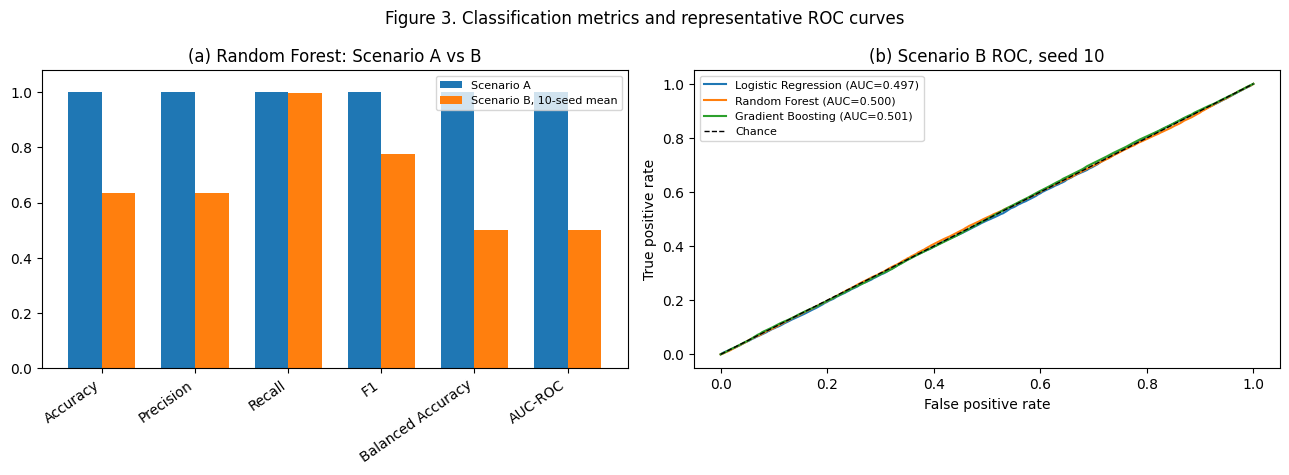

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
cols=['Accuracy','Precision','Recall','F1','Balanced Accuracy','AUC-ROC']
rf_a=scenario_a.set_index('Model').loc['Random Forest',cols].astype(float).to_numpy()
rf_b=results_summary.loc['Random Forest'].xs('mean',level=1).loc[cols].to_numpy(dtype=float)
x=np.arange(len(cols));w=0.36
axes[0].bar(x-w/2,rf_a,width=w,label='Scenario A')
axes[0].bar(x+w/2,rf_b,width=w,label='Scenario B, 10-seed mean')
axes[0].set_xticks(x,cols,rotation=35,ha='right');axes[0].set_ylim(0,1.08)
axes[0].set_title('(a) Random Forest: Scenario A vs B');axes[0].legend(fontsize=8)
for name in MODELS:
    fpr,tpr,_=curve_data[name]
    axes[1].plot(fpr,tpr,label=f'{name} (AUC={REP[name]["metrics"]["AUC-ROC"]:.3f})')
axes[1].plot([0,1],[0,1],'k--',lw=1,label='Chance')
axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title='(b) Scenario B ROC, seed 10')
axes[1].legend(fontsize=8);fig.suptitle('Figure 3. Classification metrics and representative ROC curves')
plt.tight_layout();plt.show()

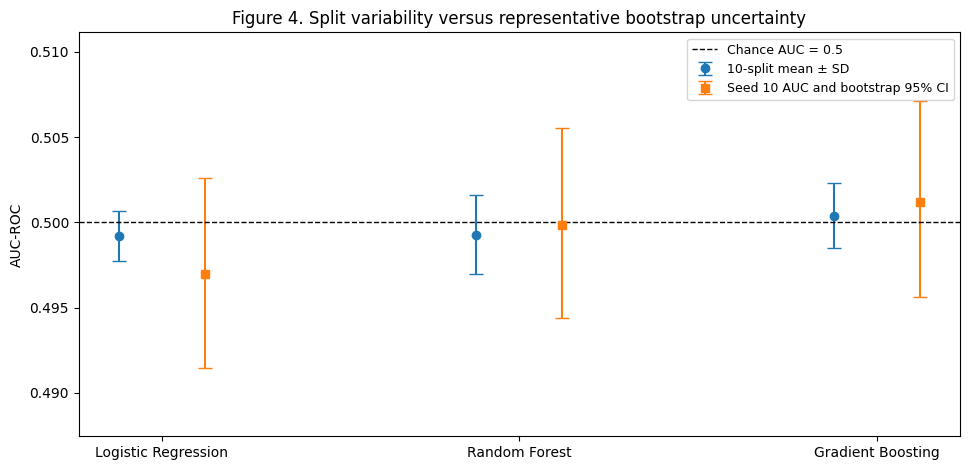

In [8]:
fig,ax=plt.subplots(figsize=(9.8,4.8))
means=np.array([results_summary.loc[m,('AUC-ROC','mean')] for m in MODELS])
sds=np.array([results_summary.loc[m,('AUC-ROC','std')] for m in MODELS])
lo=np.array([bootstrap_table.loc[m,'Bootstrap CI low'] for m in MODELS])
hi=np.array([bootstrap_table.loc[m,'Bootstrap CI high'] for m in MODELS])
rep=np.array([bootstrap_table.loc[m,'Representative AUC'] for m in MODELS])
x=np.arange(3)
ax.errorbar(x-0.12,means,yerr=sds,fmt='o',capsize=5,label='10-split mean ± SD')
ax.errorbar(x+0.12,rep,yerr=[rep-lo,hi-rep],fmt='s',capsize=5,label='Seed 10 AUC and bootstrap 95% CI')
ax.axhline(0.5,color='black',linestyle='--',linewidth=1,label='Chance AUC = 0.5')
ax.set_xticks(x,MODELS);ax.set_ylabel('AUC-ROC');ax.set_ylim(min(lo.min()-.004,.49),max(hi.max()+.004,.51))
ax.set_title('Figure 4. Split variability versus representative bootstrap uncertainty');ax.legend(loc='best',fontsize=9)
plt.tight_layout();plt.show()

## 6. K-means, Figure 5, and Table 4

The silhouette score is calculated on a reproducible **sample of 3,000** out of 200,000 fitted observations; the Davies–Bouldin index uses all observations. If the manuscript reports a precise silhouette score, the caption must describe this sampling procedure.

d:\toolLanguage\PYTHONLANGUAGE\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\toolLanguage\PYTHONLANGUAGE\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\toolLanguage\PYTHONLANGUAGE\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "d:\toolLanguage\PYTHONLANGUAGE\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^

,k,Silhouette (sample 3000),Davies-Bouldin (full)
0,2,0.831245,0.253144
1,3,0.777071,0.363888
2,4,0.680528,0.464600
3,5,0.658949,0.473420
4,6,0.685570,0.393415
5,7,0.683357,0.410734
6,8,0.678999,0.420798


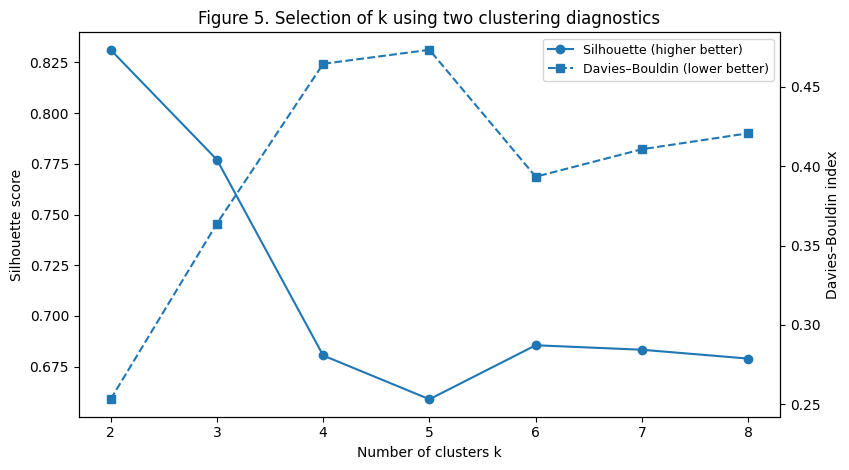

In [9]:
money_cols=['Claim Amount','Category Premium']
Z=StandardScaler().fit_transform(df[money_cols])
cluster_results=[];cluster_labels={}
for k in range(2,9):
    km=KMeans(n_clusters=k,random_state=KMEANS_SEED,n_init=10)
    labs=km.fit_predict(Z);cluster_labels[k]=labs
    sil=silhouette_score(Z,labs,sample_size=SIL_SAMPLE_SIZE,random_state=KMEANS_SEED)
    db=davies_bouldin_score(Z,labs)
    cluster_results.append({'k':k,'Silhouette (sample 3000)':sil,'Davies-Bouldin (full)':db})
cluster_scores=pd.DataFrame(cluster_results)
display(cluster_scores.round(6))
fig,ax=plt.subplots(figsize=(8.6,4.8))
ax.plot(cluster_scores['k'],cluster_scores['Silhouette (sample 3000)'],marker='o',label='Silhouette (higher better)')
ax.set(xlabel='Number of clusters k',ylabel='Silhouette score',title='Figure 5. Selection of k using two clustering diagnostics')
ax2=ax.twinx()
ax2.plot(cluster_scores['k'],cluster_scores['Davies-Bouldin (full)'],marker='s',linestyle='--',label='Davies–Bouldin (lower better)')
ax2.set_ylabel('Davies–Bouldin index')
h1,l1=ax.get_legend_handles_labels();h2,l2=ax2.get_legend_handles_labels();ax.legend(h1+h2,l1+l2,loc='best',fontsize=9)
plt.tight_layout();plt.show()

In [10]:
labels=cluster_labels[2]
# Re-label so 0 denotes high-premium, as manuscript Table 4
mean_premium=pd.DataFrame({'raw_cluster':labels,'premium':df['Category Premium']}).groupby('raw_cluster')['premium'].mean()
high_label=mean_premium.idxmax()
segment=np.where(labels==high_label,0,1)
work=df.assign(Segment=segment,Churn_binary=y)
table4=work.groupby('Segment').agg(n=('Churn_binary','size'),
                                  average_category_premium=('Category Premium','mean'),
                                  average_claim_amount=('Claim Amount','mean'),
                                  churn_rate=('Churn_binary','mean'))
display(table4)
print('Segment x premium category:');display(pd.crosstab(segment,df['Category Premium']))
contingency=pd.crosstab(segment,y)
chi2,p,dof,expected=chi2_contingency(contingency,correction=False)
print(f'Chi-square WITHOUT Yates correction: chi2={chi2:.6f}, df={dof}, p={p:.6f}')
print('Partition exactly equals Medical vs non-Medical:',np.array_equal(segment,(df['Claim Reason']!='Medical').astype(int).to_numpy()))

,n,average_category_premium,average_claim_amount,churn_rate
Segment,,,,
0,109863,14390.000000,1798.744573,0.636256
1,90137,2350.069439,293.778282,0.636487


Segment x premium category:


Category Premium,399,1875,4794,14390
row_0,,,,
0,0,0,0,109863
1,30187,30016,29934,0


Chi-square WITHOUT Yates correction: chi2=0.011380, df=1, p=0.915046
Partition exactly equals Medical vs non-Medical: True


## 7. Manuscript consistency checks and editorial notes

The assertions below confirm data-dependent facts, not identity with the unshared original author pipeline. They are intentionally strict for key count relationships and tolerant for published rounded metrics. If a check fails, inspect the output before revising text or figures.

In [11]:
checks={
    'Full data size 200,000':len(df)==200000,
    '19,373 feature vectors with BMI':len(df[FEATURES].drop_duplicates())==19373,
    '1,769 feature vectors without BMI':len(df[FEATURES_B].drop_duplicates())==1769,
    'BMI fully separates churn':(((df['BMI']<=24).astype(int)==y).all()),
    'Representative split 157,620 / 42,380':(len(train_rep),len(test_rep))==(157620,42380),
    'All three Scenario A AUC = 1':(scenario_a['AUC-ROC']>0.999999).all(),
    'Scenario B all mean AUC near chance':all(abs(results_summary.loc[m,('AUC-ROC','mean')]-.5)<.015 for m in MODELS),
    'All 3 bootstrap CIs include chance':all(bootstrap_table.loc[m,'Bootstrap CI low']<=.5<=bootstrap_table.loc[m,'Bootstrap CI high'] for m in MODELS),
    'Both cluster metrics select k=2':int(cluster_scores.loc[cluster_scores['Silhouette (sample 3000)'].idxmax(),'k'])==2 and int(cluster_scores.loc[cluster_scores['Davies-Bouldin (full)'].idxmin(),'k'])==2,
    'Cluster 0 = Medical':np.array_equal(segment,(df['Claim Reason']!='Medical').astype(int).to_numpy())
}
check_table=pd.DataFrame({'Check':list(checks),'Pass':list(checks.values())})
display(check_table)
if not all(checks.values()):warnings.warn('At least one manuscript consistency check failed; inspect carefully.')
print('\nMANUSCRIPT AUDIT NOTES:')
print('- Scenario A and B outputs belong to this notebook protocol, not necessarily the original authors’ configuration.')
print('- Table 2 must use representative seed=10 counts displayed above.')
print('- Table 3 must match rounded results_summary and Scenario A metrics.')
print('- Figure 3 uses RF 10-seed means (panel a) and ROC from seed=10 (panel b).')
print('- Figure 4 shows 10-seed SD versus observation-level seed-10 bootstrap CI (not group bootstrap).')
print('- Figure 5 silhouette computed on a sample of 3000, DBI on all records.')
print('- Table 4 is a premium proxy comparison; it does not establish retention uplift or CLV.')

,Check,Pass
0,"Full data size 200,000",True
1,"19,373 feature vectors with BMI",True
2,"1,769 feature vectors without BMI",True
3,BMI fully separates churn,True
4,"Representative split 157,620 / 42,380",True
5,All three Scenario A AUC = 1,True
6,Scenario B all mean AUC near chance,True
7,All 3 bootstrap CIs include chance,True
8,Both cluster metrics select k=2,True
9,Cluster 0 = Medical,True



MANUSCRIPT AUDIT NOTES:
- Scenario A and B outputs belong to this notebook protocol, not necessarily the original authors’ configuration.
- Table 2 must use representative seed=10 counts displayed above.
- Table 3 must match rounded results_summary and Scenario A metrics.
- Figure 3 uses RF 10-seed means (panel a) and ROC from seed=10 (panel b).
- Figure 4 shows 10-seed SD versus observation-level seed-10 bootstrap CI (not group bootstrap).
- Figure 5 silhouette computed on a sample of 3000, DBI on all records.
- Table 4 is a premium proxy comparison; it does not establish retention uplift or CLV.
